# Run Options

In [28]:
RUN_FRAGMENTATION = False
MOLECULE = 'H2S'
N_MODES = 3 # Number of Modes (for fragmentation)
data_path = 'data/H_frags_H2S_V2_3Frags.pkl' # if RUN_FRAGMENTATION, save to this location, else read fragments from this location TODO: can automate this
TRUNCATION = 4

# VQD Parameters:
num_states = 5 # Number of states to compute.
ndepth = 25 # Number of layers in the qumode circuit ansatz.
niter = 3000 # Maximum number of iterations for the optimization.
threshold = 1e-3 # Convergence threshold for the optimization.
nfocks = [64] # Designates the number of modes and number of fock states for each mode. For example, [16] means 1 mode with 16 fock states, and [16, 16] means 2 modes with 16 fock states each.

In [2]:
from pathlib import Path
data_path = Path.cwd().parent / data_path

In [3]:
# TODO: deal with making sure file paths are correct
# from pathlib import Path

# if MOLECULE == 'H2S':
#     p = Path("..") / "data" / "H2S.hdf5"
# elif MOLECULE == 'CO2':
#     p = Path("..") / "data" / "CO2.hdf5"

# if not p.exists():
#     raise FileNotFoundError(f"Vibrational Hamiltonian file not found at  {p}.\n"
#                             "Please reach out to authors of J. Phys. Chem. Lett. 2025, 16, 8, 1855–1864 for access to the data.\n"
#                             "Alternativley, recreate the data using ")

# Prerequisite

In [4]:
from silence_tensorflow import silence_tensorflow
silence_tensorflow()

I0000 00:00:1779216690.681930   34204 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1779216690.683254   34204 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1779216692.871346   34204 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1779216692.874021   34204 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [5]:
import tensorflow as tf

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.21.0
GPU available: []


# Vibrational Hamiltonian

## prereqs

In [6]:
import numpy as np
import time

from third_party.vibrational_dynamics.util_hamil import operator_quad, hamil
from third_party.vibrational_dynamics.util_gfro import (
    norm_m,
    obtain_fragment,
    fragments,
    subtract,
    non_rotated_fragments,
    recreate_matrices,
    vectors,
    super_matrix_exp,
    extract_sub_matrices,
    tranformed_operators,
    compute_fragment,
    initial,
    flatten_matrices,
)
from third_party.vibrational_dynamics.util_qudratic import b_transform, recreate_quadH

from scipy.optimize import minimize



# Hamiltonian in the form of OpenFermion bosonic operator can be created with two functions
# "operator_quad" function creates hamiltonian generated with Gaussian
# "hamil" function creates hamiltonian provided by Xanadu

name = "H2S"

# H = operator_quad(name) # Hamiltonian in OpenFermion bosonic operator form
# Options are "CO","CO2","NH3",
# model_hamiltonians options "D2","D3"

H = hamil(name)  # Hamiltonian in OpenFermion bosonic operator form
# Options are "H2S","CO2","CH4","H2S_3c","CO2_3c"
# "H2S_3c","CO2_3c" are with 3 mode coupling


n = N_MODES  # Number of modes

params = list()
norms = list()


# calculating the cost function(sum of square of the coeffiecients of H-H_f operator)


def cost(X):

    P, Q, G, L = recreate_matrices(X, n)  # Calculate P,Q,G,L from paramter vector X

    expA = super_matrix_exp(P, Q)  # Calculate exp([[P,Q],[Q,P]])

    U, V = extract_sub_matrices(
        expA, n
    )  # Extract U and V from exp([[P,Q],[Q,P]]) = [[U,-V],[-V,U]]

    C_b, C_bd = tranformed_operators(U, V, G)  # Calculate transformed operators

    H_f = compute_fragment(
        L, C_b, C_bd, n
    )  # Calculate quartic fragments from calculated L, C_b, C_bd

    H_vector, H_f_vector, sorted_ops = vectors(
        H, H_f
    )  # extract coeffiecients and corresponding operators from H and H_f

    # Finding indices corresponds to cubic and quartic terms in the Hamiltonian and the Fragment
    indices_cq = [i for i, op in enumerate(sorted_ops) if len(op) == 3 or len(op) == 4]

    cost_fn = []

    for i in indices_cq:
        value = H_vector[i] - H_f_vector[i]
        value = np.float64(value)
        value_sq = value**2
        cost_fn.append(value_sq)

    cost = np.real(np.sqrt((sum(cost_fn))))

    return cost


def printx(x):
    global iteration_count
    iteration_count += 1
    cost_value = cost(x)
    with open(f"{name}.txt", "a") as f:
        f.write(f"Step {iteration_count}: cost = {cost_value}\n")
    print(f"Step {iteration_count}: cost = {cost_value}")


current_norm = norm_m(H)
norms.append(current_norm)
print(" Norm of cubic and quartic terms")
print(f"\nInitial Norm : {current_norm}")


numtag = 3 # was 4
tol = 1e-5
num_fragments = len(params)

options = {"maxiter": 1000, "disp": True} # was "maxiter": 1000


 Norm of cubic and quartic terms

Initial Norm : 984427.3780520973


## Run Fragmentation

In [7]:
Xs = []

In [8]:
if RUN_FRAGMENTATION:
  start_time = time.time()

  iteration_count = 0

  for k in range(numtag):

      # end decomposition if remaining norm is less than tol
      if current_norm < tol:
          print("Completed!!")
          break

      # obtain fragment

      P, Q, G, L = initial(n)
      X = 1e-3 * flatten_matrices(P, Q, G, L, n)
      Xs.append(X)

      result = minimize(
          cost, X, method="BFGS", tol=1e-7, options=options
      )  # , callback=printx)

      # obtain fragment from parameters in bosonic form
      H_f = fragments(result.x, n)

      # remove fragment from H
      H = subtract(H, H_f)

      current_norm = norm_m(H)

      # save current parameters and current norm
      params.append(result.x)

      norms.append(current_norm)

      num_fragments += 1

      print(
          f"fragment count : {num_fragments}, current norm : {np.round(current_norm, 7)}"
      )


  U, V, L, G, K = b_transform(H, n)  # params for the last fragment

  # Recreate the last fragment (qudratic)
  Hquad = recreate_quadH(U, V, L, G, K, n)

  end_time = time.time()
  elapsed_time = end_time - start_time
  print(f"Runtime : {elapsed_time}")


## Post-Processing

In [9]:
if RUN_FRAGMENTATION:
  H_f = fragments(params[0], n)
  H_frags = [fragments(param, n) for param in params]

### Save to File

In [10]:
import pickle

In [11]:
if RUN_FRAGMENTATION:
  with open(data_path, "wb") as f:
      pickle.dump(params, f)

## import fragments, construct H_eff

In [12]:
import pickle

In [13]:
def sub_frags(H_target):
  for i in range(len(H_frags)):
    H_target = subtract(H_target, H_frags[i])
  return H_target

In [14]:
with open(data_path, "rb") as f:
  loaded_params = pickle.load(f)

H_frags = [fragments(param, n) for param in loaded_params]
H_0 = sub_frags(H)
H_eff = sum(H_frags) + H_0
H_frags.append(H_0)

In [15]:
print(data_path)          # confirm the full path
print(data_path.exists()) # confirm the file is actually there

/mnt/c/Users/marlo_2lbtn5r/OneDrive/School/Dong Lab/Beckman Project/Code/QumVQD Repo/QumVQD/data/H_frags_H2S_V2_3Frags.pkl
True


## Bosonic Op Conversion

In [16]:
trunc = TRUNCATION

In [17]:
from openfermion.linalg import boson_operator_sparse

H_frags_sparse = [boson_operator_sparse(H_frag, trunc=trunc) for H_frag in H_frags]

In [18]:
import tensorflow as tf

H_frags_tf = [tf.constant(H_frag.todense(), dtype=tf.complex128) for H_frag in H_frags_sparse]

## Diagonalization

### H_eff

In [19]:
H_eff_sparse = boson_operator_sparse(H_eff, trunc=trunc)

In [20]:
H_eff_eigenenergies = np.linalg.eigvalsh(H_eff_sparse.todense())

### H from file

In [21]:
H_original_sparse = boson_operator_sparse(H, trunc=4)
H_original_eigenenergies = np.linalg.eigvalsh(H_original_sparse.todense())
H_original_eigenenergies[:num_states]

array([3302.14145874, 4563.81441477, 5807.74635477, 5840.77395045,
       5900.55015796])

### Comparison

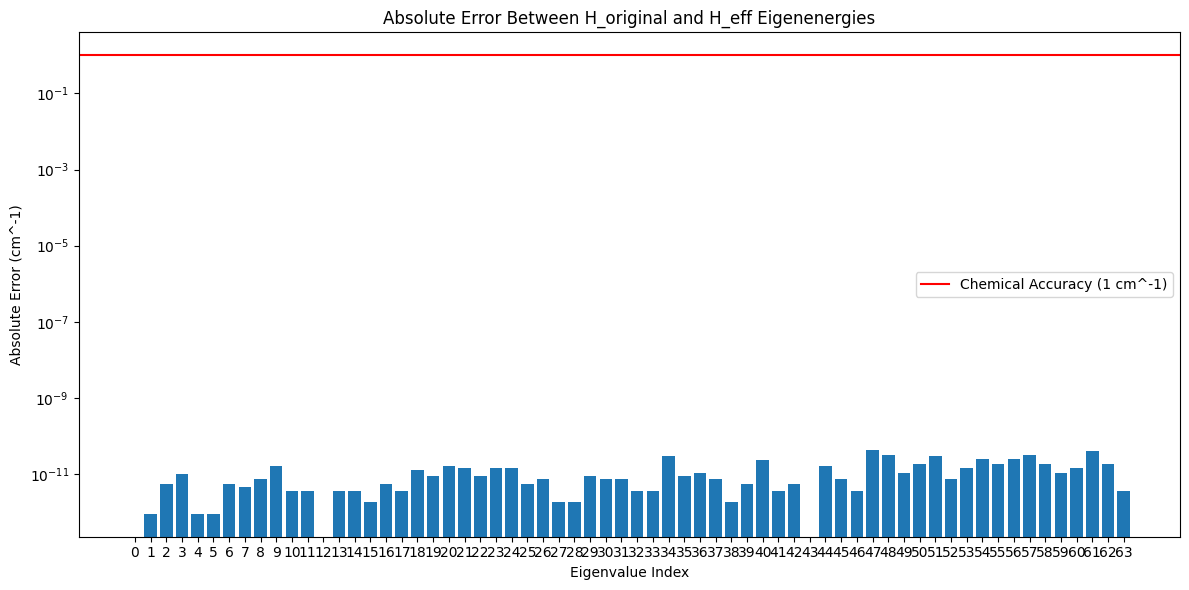

In [22]:
import matplotlib.pyplot as plt
import numpy as np

original_subset = H_original_eigenenergies[:len(H_eff_eigenenergies)]
eff_subset = H_eff_eigenenergies

errors = np.abs(original_subset - eff_subset)

labels = [f'{i}' for i in range(len(errors))]

x = np.arange(len(errors))

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(x, errors)

ax.set_ylabel('Absolute Error (cm^-1)')
ax.set_xlabel('Eigenvalue Index')
ax.set_title('Absolute Error Between H_original and H_eff Eigenenergies')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_yscale('log')

# Add a horizontal line at y=1 (chemical accuracy)
ax.axhline(y=1, color='r', linestyle='-', label="Chemical Accuracy (1 cm^-1)")

ax.legend()
fig.tight_layout()
plt.show()

# Run QumVQD

In [29]:
from helpers.QumVQD_Helpers import *

In [ ]:
beta_factor = 4.0 * norm_m(H_eff)
H_eff_tf = [tf.constant(H_eff_sparse.todense(), dtype=tf.complex128)]
H_ops = H_eff_tf # Can use H_frags_tf or H_eff_tf
coeffs = np.ones(len(H_ops))

energies, state_params, results, psis = find_excited_states_multi_qumode(
    H_ops = H_ops, coeffs = coeffs, ndepth = ndepth,
    num_states = num_states, beta_factor=beta_factor,
    niter=niter, threshold=threshold, nfocks=nfocks, save_files=True, save_dir=f"output_data/{name}_VQD_results"
)

print("Energies found:", energies)

num_prev_states = 0

Finding state 0...


In [ ]:
en = [float(energy) for energy in energies]
print(en)

[5341.46151077333, 14165.175003135155, 15087.113258317673, 14085.092373785223, 14149.477335842806]
